In [4]:
# ==========================================
# AI-POWERED FX RISK INTELLIGENCE PLATFORM
# Week 2 - Session 3
# GARCH(1,1) Modelling and Forecasting
# ==========================================

%pip install arch

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from arch import arch_model

# Load dataset
df = pd.read_csv("../data/processed/cleaned_fx_data.csv")

# Currency pairs
currency_pairs = {"GBP/USD": "GBPUSD_Close", "EUR/USD": "EURUSD_Close", "USD/JPY": "USDJPY_Close"}

# Calculate logarithmic returns
returns = pd.DataFrame()
for pair, column in currency_pairs.items():
    returns[pair] = np.log(df[column] / df[column].shift(1)) * 100
returns = returns.dropna()
print(returns.head())



Note: you may need to restart the kernel to use updated packages.
    GBP/USD   EUR/USD   USD/JPY
1  0.567410  0.313133  0.094725
2 -1.369526 -0.521349 -0.204471
3 -0.128376  0.116775 -0.318505
4  0.541373  0.195714 -0.194947
5 -0.033225  0.034775 -0.302429



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
garch_results = {}
forecast_results = {}
comparison = []
for pair in returns.columns:

    # Build GARCH(1,1) model
    model = arch_model(
        returns[pair],
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    # Estimate model
    fit = model.fit(disp="off")

    # Store fitted model
    garch_results[pair] = fit

    # Extract parameters
    omega = fit.params["omega"]
    alpha = fit.params["alpha[1]"]
    beta = fit.params["beta[1]"]
    persistence = alpha + beta

    # Calculate long-run volatility
    if persistence < 1:
        long_run_vol = np.sqrt(omega / (1 - persistence))
    else:
        long_run_vol = np.nan

    # Five-day forecast
    forecast = fit.forecast(horizon=5)
    volatility = np.sqrt(forecast.variance.iloc[-1])
    forecast_results[pair] = volatility

    # Store results
    comparison.append({
        "Currency Pair": pair,
        "Omega": omega,
        "Alpha": alpha,
        "Beta": beta,
        "Persistence": persistence,
        "Long-run Volatility": long_run_vol
    })

# Display comparison
comparison_df = pd.DataFrame(comparison)
print(comparison_df.round(5))

  Currency Pair    Omega    Alpha     Beta  Persistence  Long-run Volatility
0       GBP/USD  0.00313  0.04891  0.93916      0.98807              0.51229
1       EUR/USD  0.00187  0.03737  0.95422      0.99159              0.47144
2       USD/JPY  0.01346  0.06312  0.90326      0.96638              0.63274


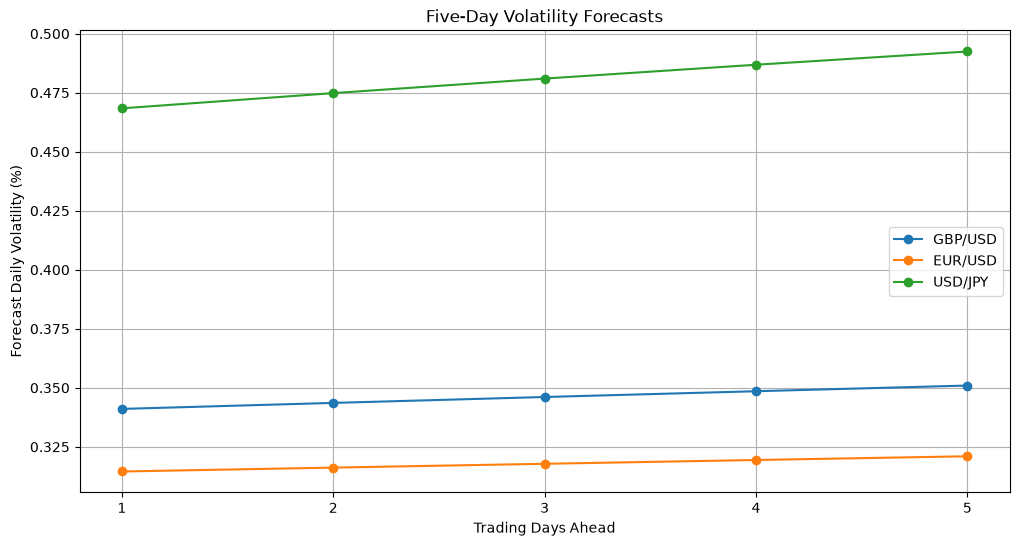

In [16]:
# Create figure of the three currency pair forecasts
plt.figure(figsize=(12,6))

# Loop through each currency pair forecast
for pair, forecast in forecast_results.items():

    # Plot forecasted volatility across five trading days
    plt.plot(
        range(1, 6),
        forecast.values,
        marker="o",
        label=pair
    )

# Add chart title and axis labels
plt.title("Five-Day Volatility Forecasts")
plt.xlabel("Trading Days Ahead")
plt.ylabel("Forecast Daily Volatility (%)")

# Display trading days 1-5 on the x-axis
plt.xticks(range(1, 6))

# Display currency pair labels
plt.legend()

# Add gridlines
plt.grid(True)

# Display chart
plt.show()

In [ ]:
# Create an empty list to store evaluation results
evaluation_results = []

# Loop through each currency pair
for pair in returns.columns:
    print(f"\nProcessing {pair}...")

    # Extract returns for current currency pair
    series = returns[pair].dropna()

    # Calculate 80/20 training and testing split
    split = int(len(series) * 0.8)

    # Define the training dataset
    train_returns = series.iloc[:split]

    # Define the testing dataset
    test_returns = series.iloc[split:]

    # Build GARCH(1,1) model using training data only
    model = arch_model(
        train_returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    # Estimate model parameters
    fit = model.fit(disp="off")

    # Generate one-day-ahead forecasts
    forecast = fit.forecast(
        horizon=1,
        start=0,
        reindex=False
    )

    # Extract forecast variance
    # The final training forecast predicts the first test observation
    predicted_variance = forecast.variance["h.1"].iloc[-1]

    # Store actual and predicted variance for the first test observation

    # Additional rolling forecasts are generated below

    # Initialise list for rolling forecasts
    predicted_values = []

    # Generate forecasts using an expanding estimation window
    for i in range(len(test_returns)):

        # Include all observations available up to the forecast origin
        current_train = series.iloc[:split + i]

        # Re-estimate GARCH model using available historical data
        current_model = arch_model(
            current_train,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist="normal"
        )
        current_fit = current_model.fit(disp="off")

        # Forecast variance for the next trading day
        current_forecast = current_fit.forecast(horizon=1)

        # Save the one-day-ahead variance forecast
        predicted_values.append(
            current_forecast.variance.iloc[-1, 0]
        )

    # Convert forecasts into a Series with matching test dates
    predicted_variance = pd.Series(
        predicted_values,
        index=test_returns.index
    )

    # Calculate actual squared returns
    actual_variance = test_returns ** 2

    # Combine actual and predicted variance
    results = pd.DataFrame({
        "Actual": actual_variance,
        "Predicted": predicted_variance
    }).dropna()

    # Check number of observations
    print("Testing observations:", len(test_returns))
    print("Matched forecasts:", len(results))

    # Metric 1 - Mean Squared Error (MSE)

    mse = np.mean(
        (results["Actual"] - results["Predicted"]) ** 2
    )

    # Metric 2 - QLIKE loss

    predicted = results["Predicted"].clip(lower=1e-10)
    actual = results["Actual"]

    qlike = np.mean(
        actual / predicted
        - np.log(actual / predicted) - 1
    )

    # Store results for current currency pair
    evaluation_results.append({
        "Currency Pair": pair,
        "MSE": mse,
        "QLIKE": qlike
    })

# Display final comparison

evaluation_df = pd.DataFrame(evaluation_results)
print("\nGARCH Forecasting Performance Comparison")
print(evaluation_df.round(6))


Processing GBP/USD...
Testing observations: 260
Matched forecasts: 260

Processing EUR/USD...
Testing observations: 260
Matched forecasts: 260

Processing USD/JPY...
Testing observations: 260
Matched forecasts: 260

GARCH Forecasting Performance Comparison
  Currency Pair       MSE     QLIKE
0       GBP/USD  0.066180  1.460641
1       EUR/USD  0.043597  1.442046
2       USD/JPY  0.364251  2.008001
